- To look at basic QC metrics

- To refine annoations of cell subtypes (based on Azimuth predicted.celltype.l2) by calc DEGs (and check with literature markers), and by mapping from ref CD4 T dataset (because it is more refined)

Found out:
1. Results do not change much re-running Azimuth - it is actually not getting better as it predicts platelets within B cells, indicating that using global reference is not optimal when running within single major cell types. Thus using original Azimuth annotation
2. Re-examine per doublet status - re-ran scrublet-R, and excluded some doublets - it turned out this re-run is not with better results (ie, to distinguish doublet clusters) - b/c previous runs are within single sample and current is within one major cell type across single samples thus affected by batch effect. Thus Thus using original scrublet annotation

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'CD4 T'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 168410 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



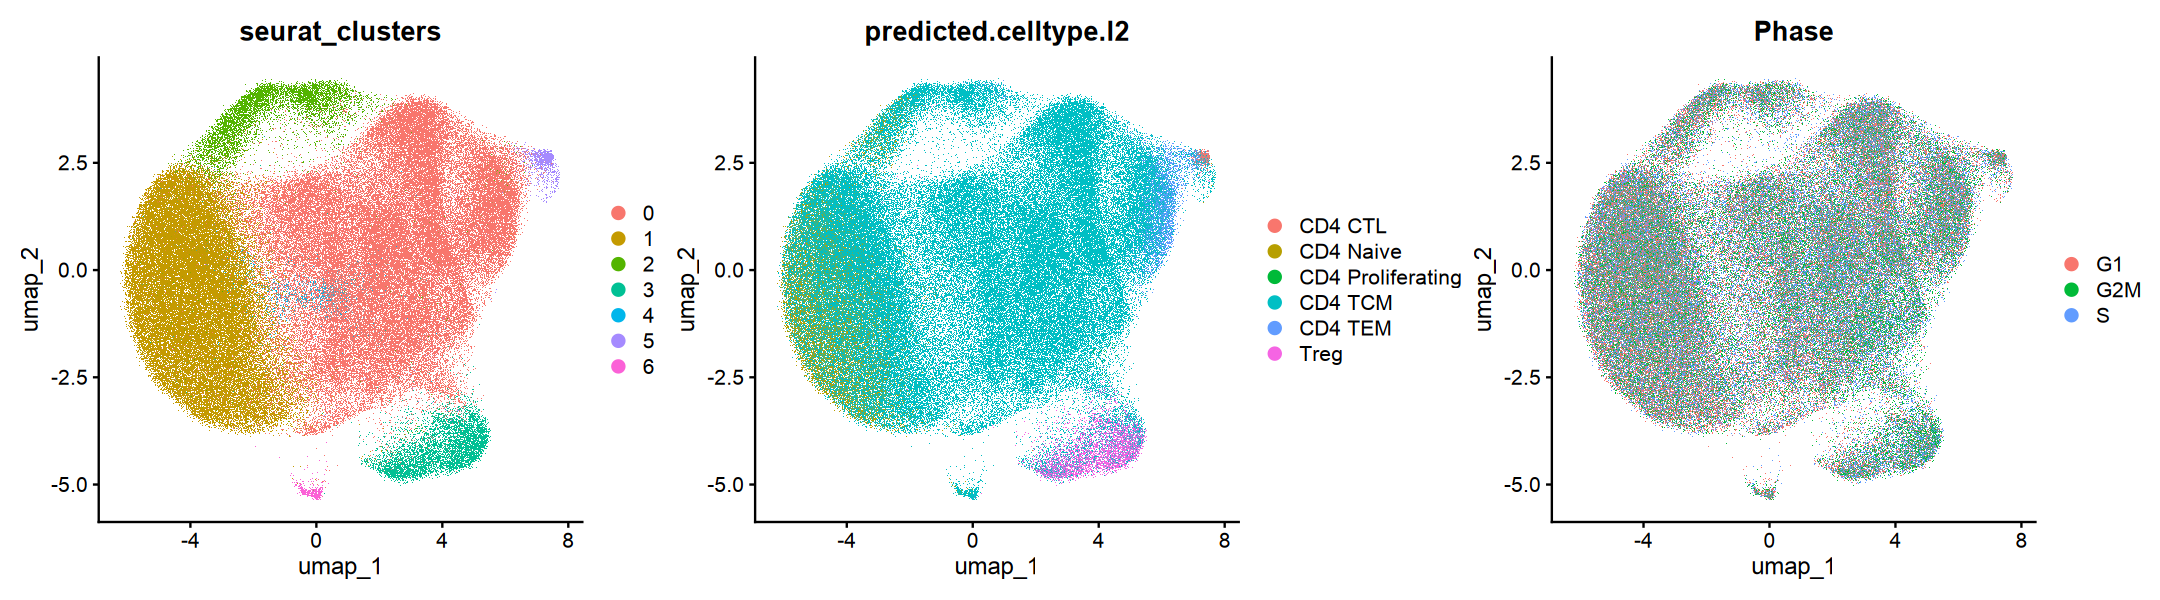

In [15]:
options(repr.plot.width=18, repr.plot.height=5)


DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2','Phase'),
        ncol=3
       )

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



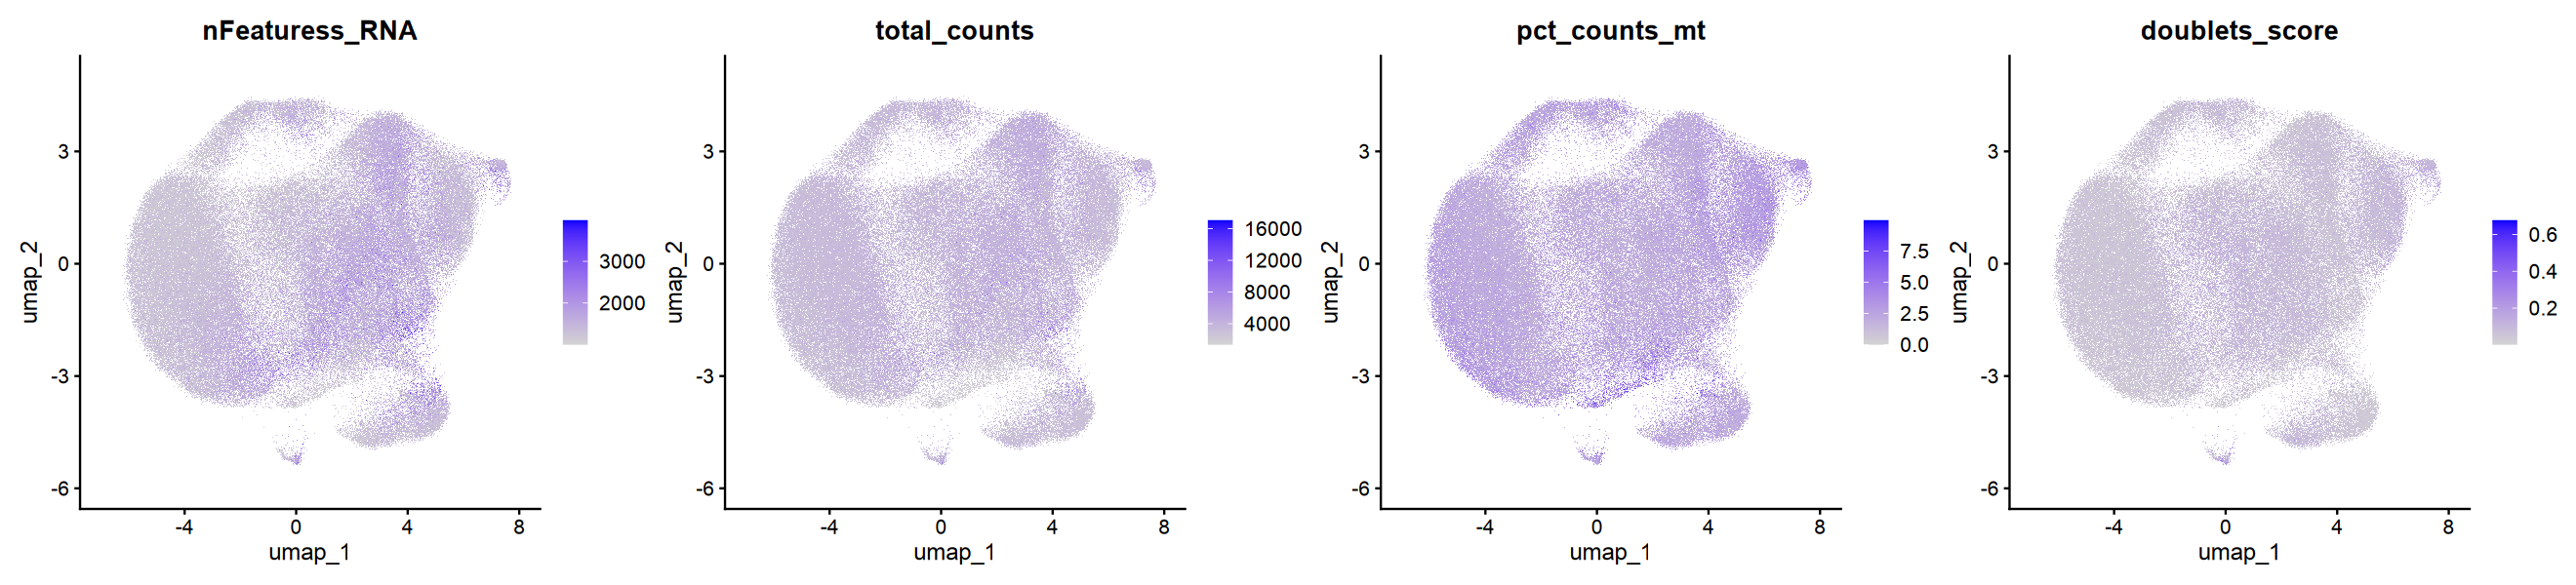

In [9]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



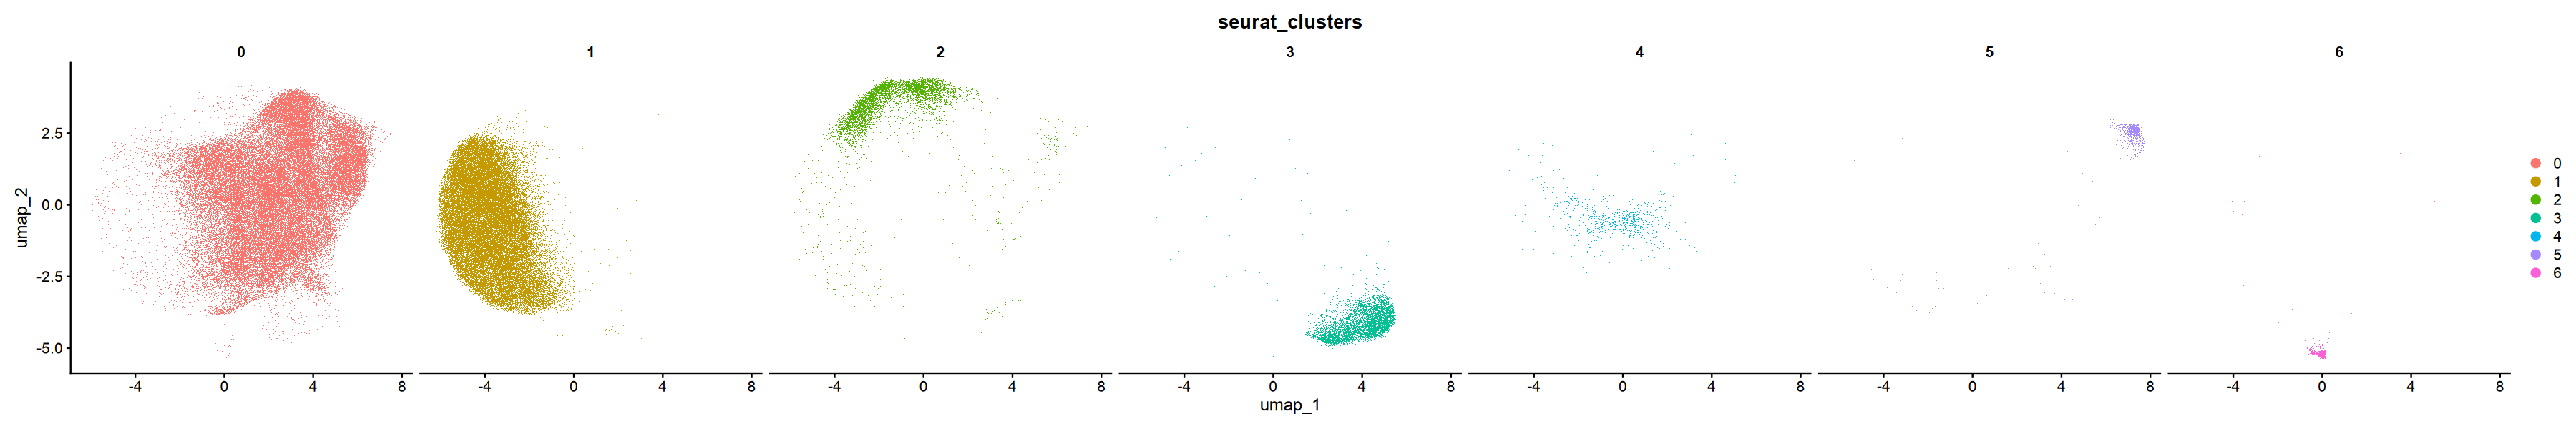

In [11]:
options(repr.plot.width=30, repr.plot.height=5)

varname = 'seurat_clusters'
DimPlot(obj, reduction = "umap",  
        group.by = varname,
        split.by = varname)

In [36]:
anno1 = obj@meta.data[,c('Phase','seurat_clusters')]

anno1 <- anno1 %>%
  mutate(celltype_level3 = case_when(
    seurat_clusters == 1 ~ "Naive CD4T",
    seurat_clusters == 3 ~ "Treg",
    seurat_clusters == 5 ~ "Cytotoxic CD4T",
    TRUE ~ "-1"
  ))

anno1 = anno %>% filter(celltype_level3 != '-1')
anno1

,Phase,seurat_clusters,celltype_level3
,<chr>,<fct>,<chr>
Pool137_10_AAACCTGAGACTCGGA-1,G1,1,Naive CD4T
Pool137_10_AAACCTGAGCTGCGAA-1,G2M,1,Naive CD4T
Pool137_10_AAACCTGGTAGGACAC-1,S,1,Naive CD4T
Pool137_10_AAACCTGGTTCCACAA-1,G1,1,Naive CD4T
Pool137_10_AAACGGGCACACGCTG-1,S,5,Cytotoxic CD4T
Pool137_10_AAACGGGCATATACGC-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGACACTAA-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGATCCGAG-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAACATAGGATA-1,G2M,1,Naive CD4T


In [22]:
ft = subset(obj, seurat_clusters %in% c(0,2,4,6))

ft

An object of class Seurat 
28202 features across 98115 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 98115
Number of edges: 1692222

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8692
Number of communities: 10
Elapsed time: 22 seconds


Warning message:
“Adding a command log without an assay associated with it”


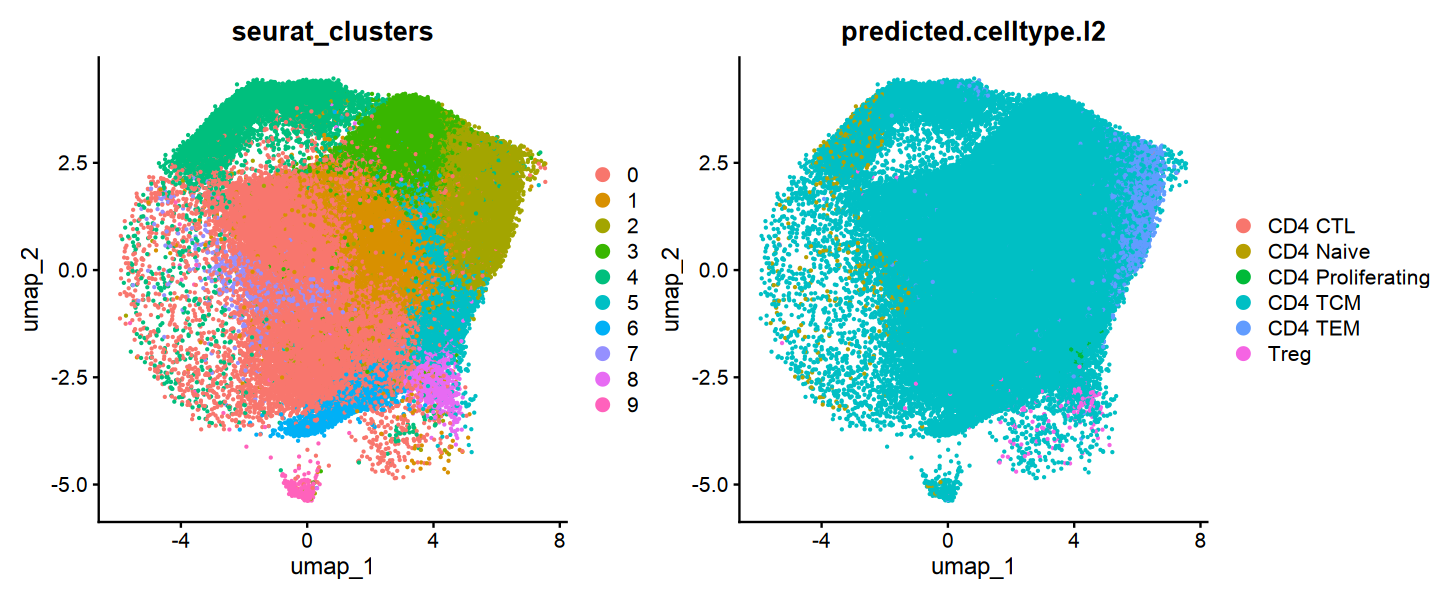

In [29]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .3)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        pt.size = .001,
        ncol=2
       )

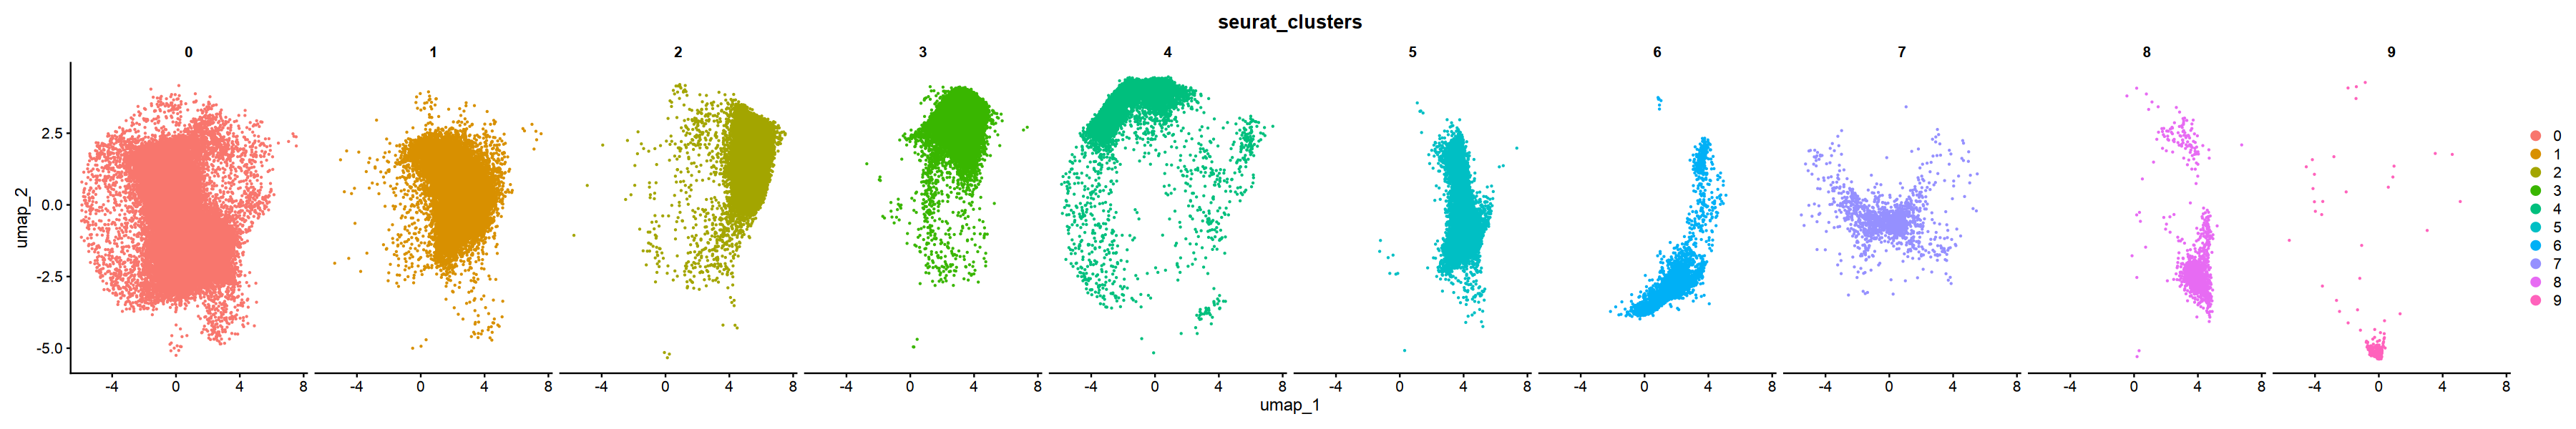

In [32]:
options(repr.plot.width=30, repr.plot.height=5)

varname = 'seurat_clusters'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname
        
       )

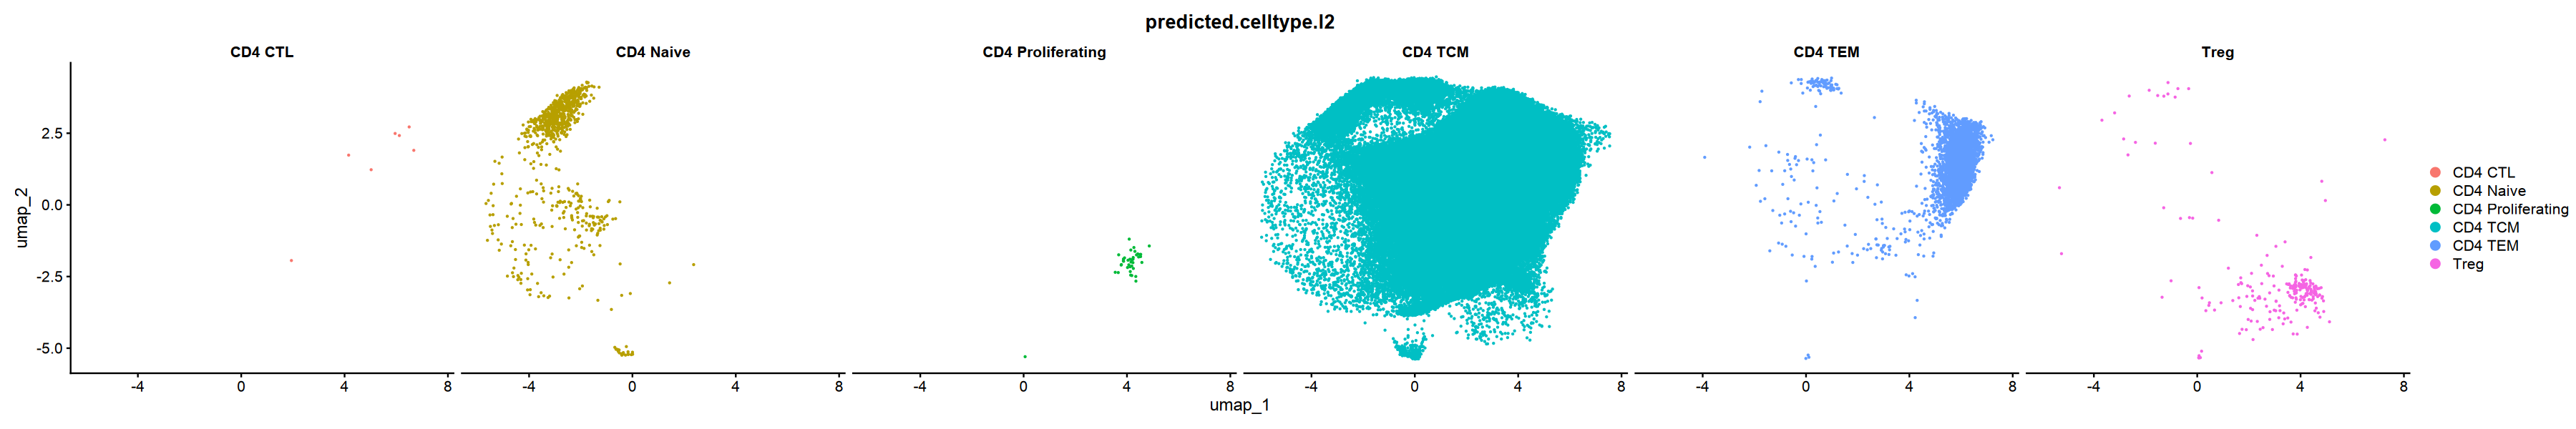

In [33]:
options(repr.plot.width=30, repr.plot.height=5)

varname = 'predicted.celltype.l2'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname
        
       )

In [35]:
anno2 <- ft@meta.data[,c('Phase','seurat_clusters')] %>%
  mutate(celltype_level3 = case_when(
    seurat_clusters == 2 ~ "Effector Memory CD4T",
    TRUE ~ "Central Memory CD4T"
  ))

anno2

,Phase,seurat_clusters,celltype_level3
,<chr>,<fct>,<chr>
Pool137_10_AAACCTGCAGGAATCG-1,S,0,Central Memory CD4T
Pool137_10_AAACCTGGTACGAAAT-1,G2M,1,Central Memory CD4T
Pool137_10_AAACCTGGTAGTACCT-1,G1,1,Central Memory CD4T
Pool137_10_AAACCTGGTGAACCTT-1,G1,0,Central Memory CD4T
Pool137_10_AAACCTGTCATCGGAT-1,G2M,5,Central Memory CD4T
Pool137_10_AAACCTGTCTCGTTTA-1,G1,4,Central Memory CD4T
Pool137_10_AAACGGGAGCAGGTCA-1,G2M,3,Central Memory CD4T
Pool137_10_AAACGGGCATGGTAGG-1,G1,0,Central Memory CD4T
Pool137_10_AAACGGGGTACTTAGC-1,G1,0,Central Memory CD4T


In [37]:
anno = rbind(anno1, anno2)
anno

,Phase,seurat_clusters,celltype_level3
,<chr>,<fct>,<chr>
Pool137_10_AAACCTGAGACTCGGA-1,G1,1,Naive CD4T
Pool137_10_AAACCTGAGCTGCGAA-1,G2M,1,Naive CD4T
Pool137_10_AAACCTGGTAGGACAC-1,S,1,Naive CD4T
Pool137_10_AAACCTGGTTCCACAA-1,G1,1,Naive CD4T
Pool137_10_AAACGGGCACACGCTG-1,S,5,Cytotoxic CD4T
Pool137_10_AAACGGGCATATACGC-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGACACTAA-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGATCCGAG-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAACATAGGATA-1,G2M,1,Naive CD4T


In [40]:
dim(obj)

[1]  27879 168410

In [42]:
# keep only cells present in the Seurat object
common <- intersect(rownames(anno), colnames(obj))
print(length(common))

# make a named vector aligned by barcode
vec <- anno[common, "celltype_level3", drop = TRUE]
names(vec) <- common

# add to metadata (cells without value become NA)
obj <- AddMetaData(obj, metadata = vec, col.name = "celltype_level3")

[1] 168410


Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


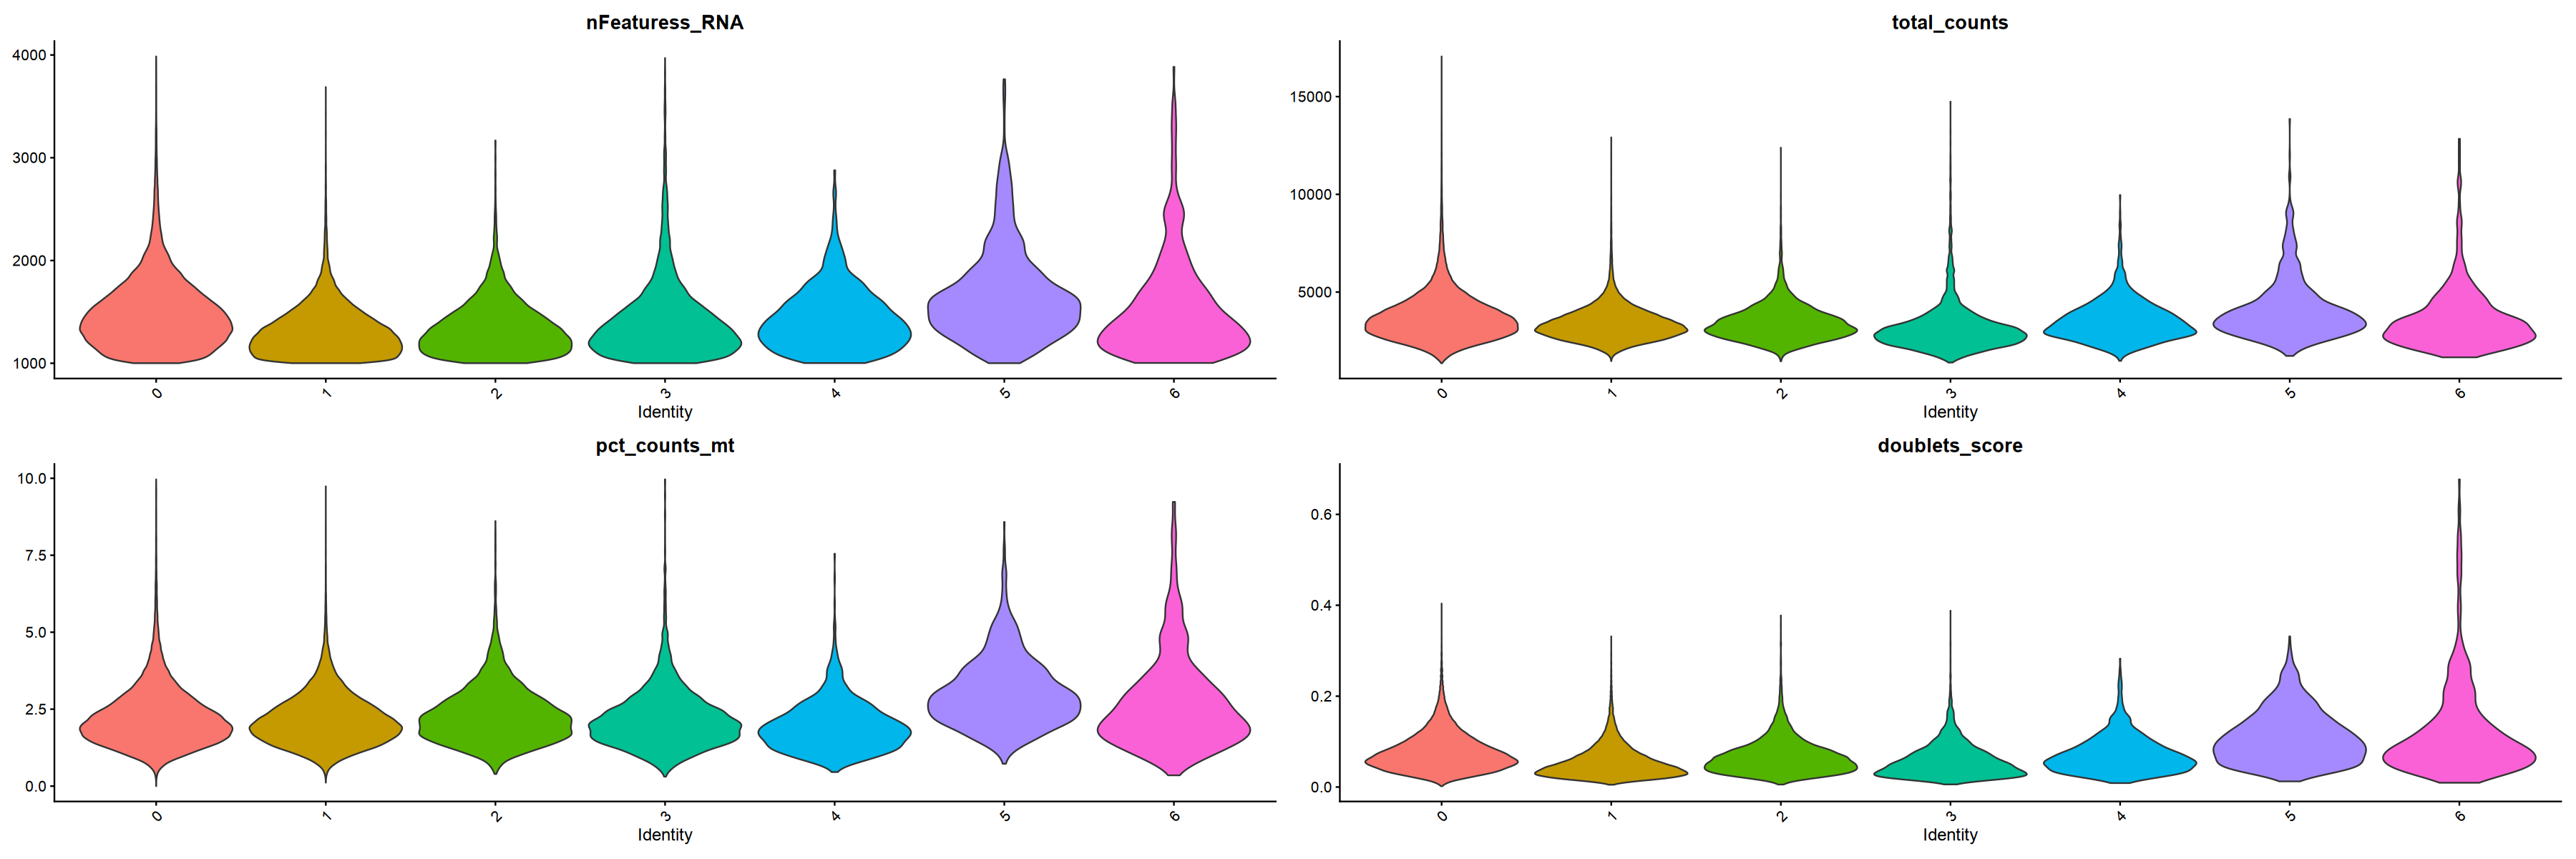

In [11]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

## Save

In [48]:
celltype = 'CD4 T'

qs::qsave(obj, glue('data/03_cleandata/ft_{celltype}.qs'))

In [4]:
celltype = 'CD4 T'
obj = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))
obj

An object of class Seurat 
28202 features across 168410 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

# Visualize

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



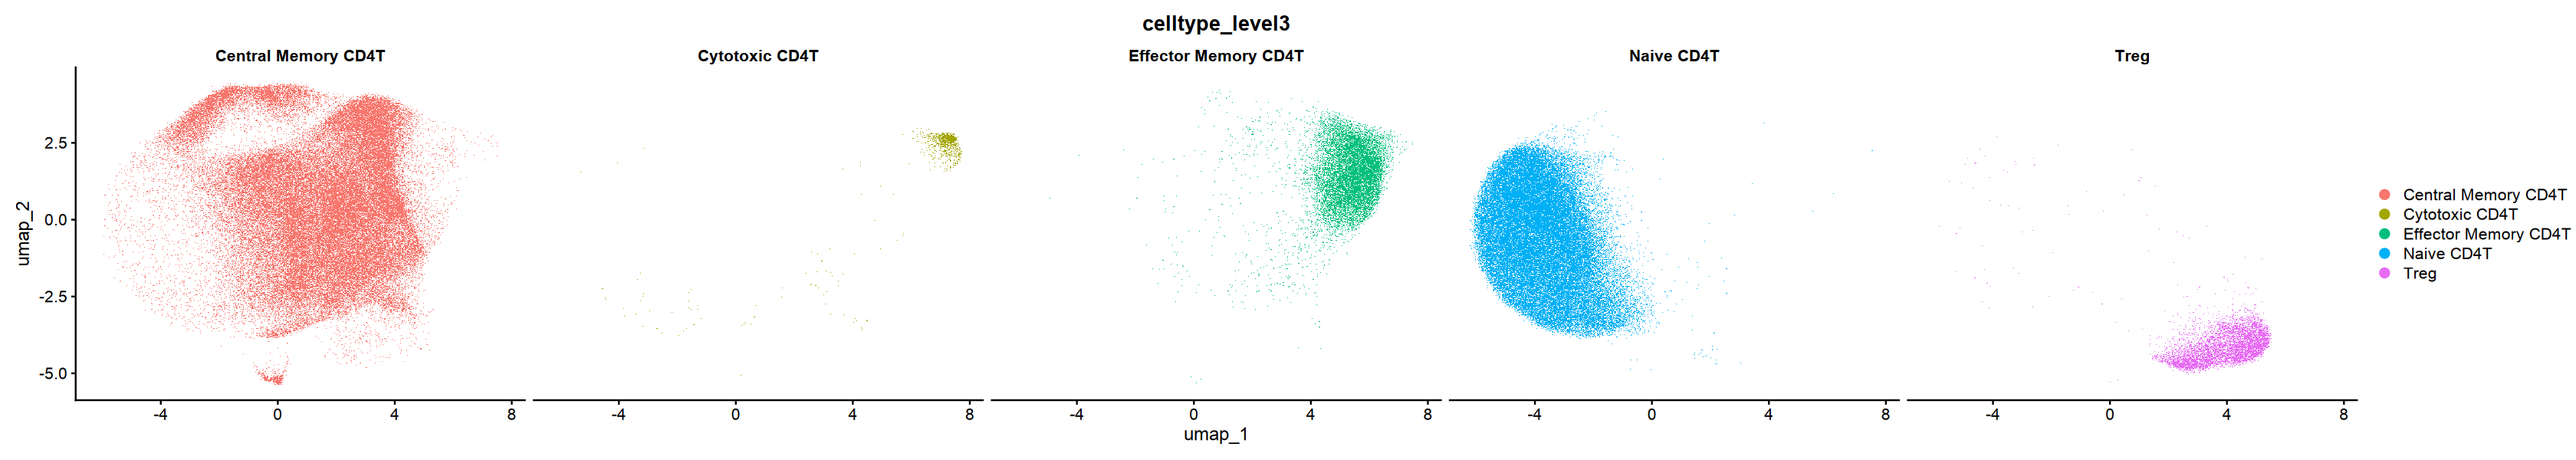

In [69]:
options(repr.plot.width=28, repr.plot.height=5)

varname = 'celltype_level3'
DimPlot(obj, reduction = "umap",  
        group.by = varname,
        split.by = varname,
        ncol = 5
       )

In [70]:
counts = table(obj@meta.data$celltype_level3)

percent <- prop.table(counts) * 100

percent


 Central Memory CD4T       Cytotoxic CD4T Effector Memory CD4T 
          49.9097441            0.6988896            8.3498605 
          Naive CD4T                 Treg 
          36.7282228            4.3132831 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



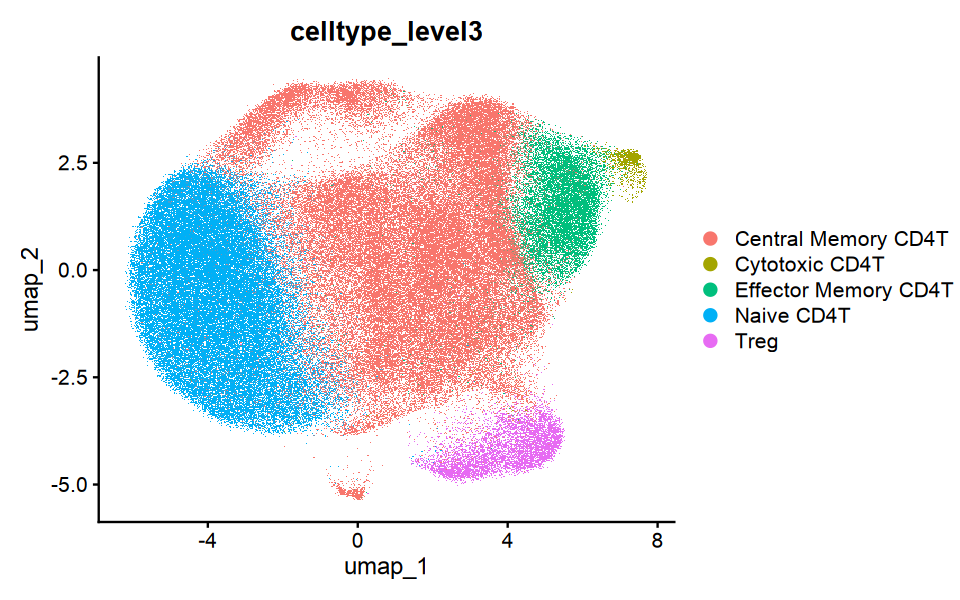

In [71]:
options(repr.plot.width=8, repr.plot.height=5)

DimPlot(obj, reduction = "umap", group.by='celltype_level3')

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



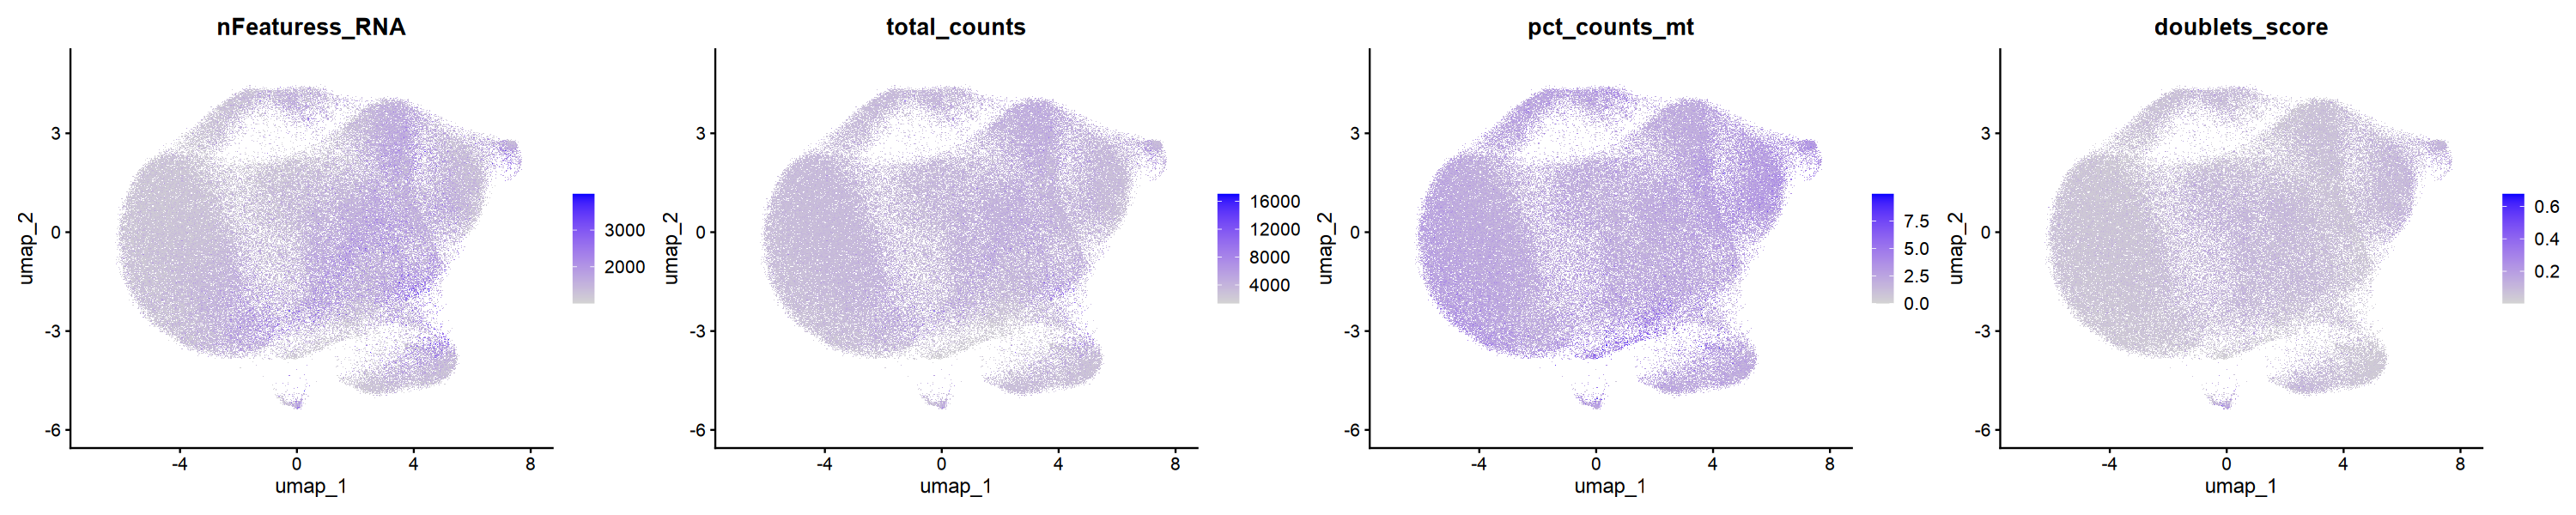

In [72]:
options(repr.plot.width=25
        , repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



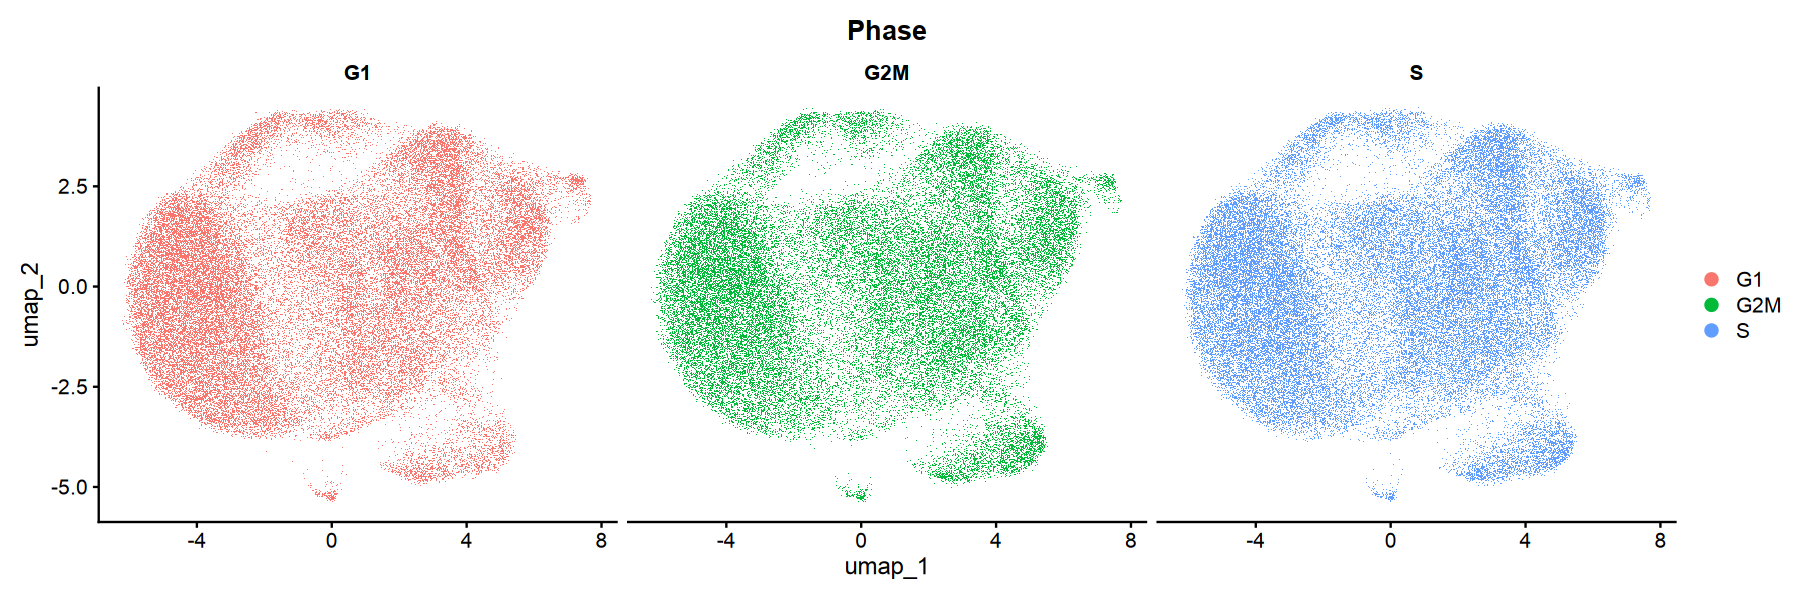

In [73]:
options(repr.plot.width=15, repr.plot.height=5)
varname = 'Phase'
DimPlot(obj, reduction = "umap",  
        group.by = varname,
        split.by = varname)

In [74]:
length(unique(ft@meta.data$dataset_name))

[1] 56

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



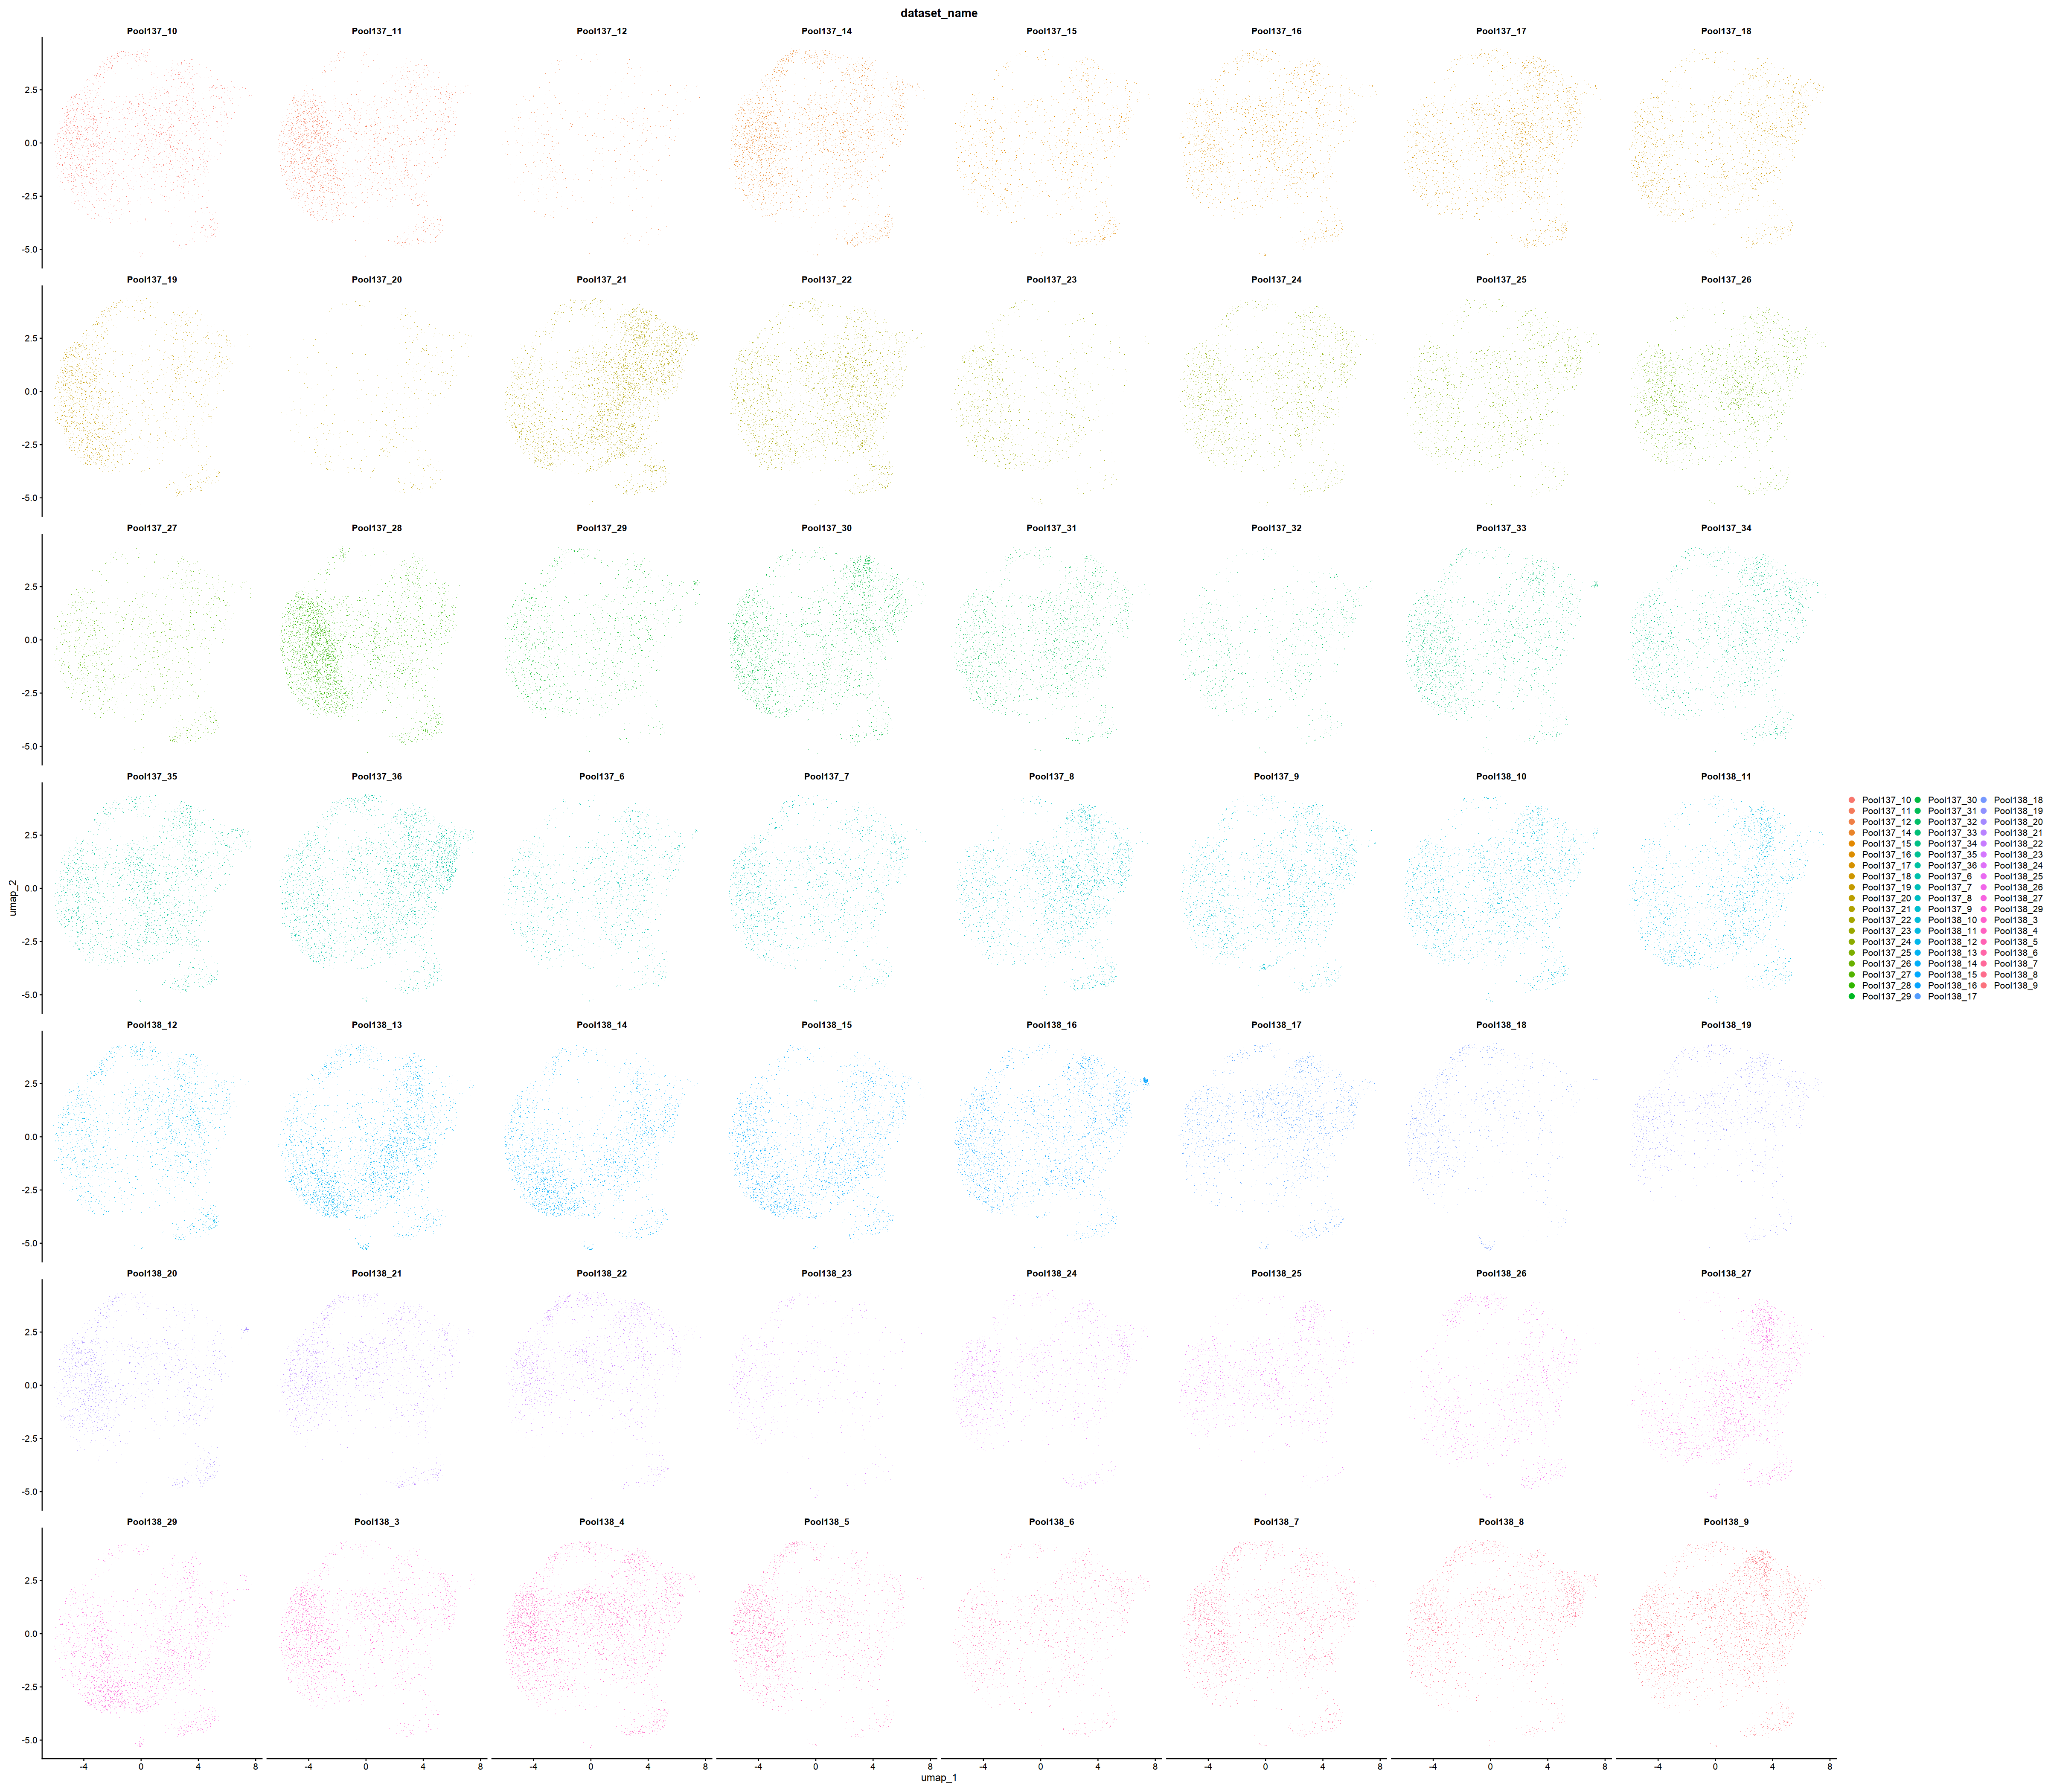

In [75]:
options(repr.plot.width=40, repr.plot.height=35)

varname = 'dataset_name'
DimPlot(obj, reduction = "umap",  
        ncol = 8,
        group.by = varname,
        split.by = varname)

# DEGs

In [54]:
obj

An object of class Seurat 
28202 features across 168410 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [56]:
Idents(obj) <- "celltype_level3"
markers <- FindAllMarkers(obj, verbose = T)
head(markers)

Calculating cluster Naive CD4T

Calculating cluster Central Memory CD4T

Calculating cluster Cytotoxic CD4T

Calculating cluster Effector Memory CD4T

Calculating cluster Treg



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ITGB1,0,-3.055631,0.113,0.594,0,Naive CD4T,ITGB1
AHNAK,0,-2.354332,0.249,0.722,0,Naive CD4T,AHNAK
S100A11,0,-2.209247,0.218,0.637,0,Naive CD4T,S100A11
S100A4,0,-2.397668,0.463,0.878,0,Naive CD4T,S100A4
FHIT,0,1.498323,0.682,0.288,0,Naive CD4T,FHIT
ANXA1,0,-1.531144,0.381,0.707,0,Naive CD4T,ANXA1


In [57]:
write.csv(markers, 
          glue('data/04_markergenes/{celltype}.csv'))

In [58]:
markers = read.csv(glue('data/04_markergenes/{celltype}.csv'),
                   row.names=1
                  )

cell_ordered = c(
    "Naive CD4T",
    "Central Memory CD4T",
    "Effector Memory CD4T",
    "Cytotoxic CD4T", 
    "Treg"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)


In [59]:
markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 10) %>%
    ungroup() -> top10

top10

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,1.498323,0.682,0.288,0,Naive CD4T,FHIT
0,1.207226,0.697,0.399,0,Naive CD4T,CCR7
0,1.113434,0.694,0.416,0,Naive CD4T,BACH2
0,1.160268,0.401,0.216,0,Naive CD4T,SATB1
0,1.365130,0.307,0.136,0,Naive CD4T,ACTN1
0,1.272691,0.330,0.160,0,Naive CD4T,NUCB2
0,1.988486,0.238,0.069,0,Naive CD4T,AIF1
0,2.314257,0.216,0.049,0,Naive CD4T,TMIGD2
0,1.029067,0.377,0.214,0,Naive CD4T,TXK


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


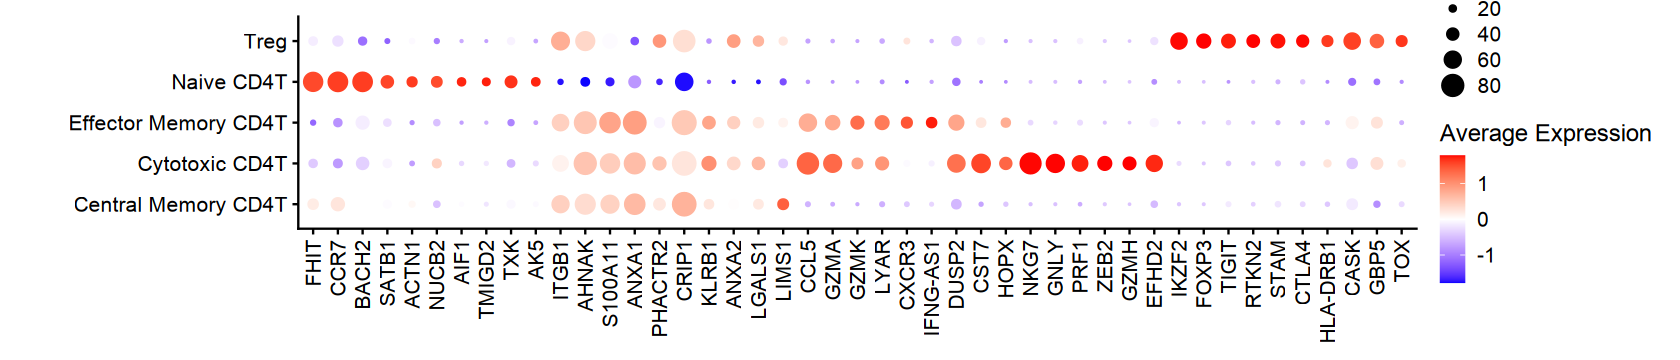

In [61]:
options(repr.plot.width=14, repr.plot.height=3)

p <- DotPlot(
  object = obj,
  features = unique(unlist(top10$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )


print(p)

In [62]:
marker_azi = read.csv('data/04_markergenes/azimuth_markers.csv')
marker_azi

Level,Label,Expanded.Label,OBO.Ontology.ID,Markers
<int>,<chr>,<chr>,<chr>,<chr>
1,Mono,Monocyte,monocyte,"CTSS, FCN1, NEAT1, LYZ, PSAP, S100A9, AIF1, MNDA, SERPINA1, TYROBP"
1,CD4 T,CD4+ T cell,"CD4-positive, alpha-beta T cell","IL7R, MAL, LTB, CD4, LDHB, TPT1, TRAC, TMSB10, CD3D, CD3G"
1,CD8 T,CD8+ T cell,"CD8-positive, alpha-beta T cell","CD8B, CD8A, CD3D, TMSB10, HCST, CD3G, LINC02446, CTSW, CD3E, TRAC"
1,NK,natural killer cell,natural killer cell,"NKG7, KLRD1, TYROBP, GNLY, FCER1G, PRF1, CD247, KLRF1, CST7, GZMB"
1,B,B cell,mature B cell,"CD79A, RALGPS2, CD79B, MS4A1, BANK1, CD74, TNFRSF13C, HLA-DQA1, IGHM, MEF2C"
1,other T,other T cell,mature T cell,"CD3D, TRDC, GZMK, KLRB1, NKG7, TRGC2, CST7, LYAR, KLRG1, GZMA"
1,DC,dendritic cell,dendritic cell,"CD74, HLA-DPA1, HLA-DPB1, HLA-DQA1, CCDC88A, HLA-DRA, HLA-DMA, CST3, HLA-DQB1, HLA-DRB1"
2,B intermediate,Intermediate B cell,mature B cell,"MS4A1, TNFRSF13B, IGHM, IGHD, AIM2, CD79A, LINC01857, RALGPS2, BANK1, CD79B"
2,B memory,Memory B cell,memory B cell,"MS4A1, COCH, AIM2, BANK1, SSPN, CD79A, TEX9, RALGPS2, TNFRSF13C, LINC01781"


In [63]:
names_sel <- c(
  "CD4 Naive", 
  "CD4 TCM", 
  "CD4 TEM", 
  "CD4 CTL", 
  "Treg"
    )  # <- your cell types of interest

# Filter marker_azi for the selected labels
marker_df <- marker_azi %>% 
filter(Level == 2) %>%
filter(Label %in% names_sel)

# Split the comma-separated Markers into list elements, assign names
markers <- setNames(
  strsplit(marker_df$Markers, ",\\s*"),   # split each marker by comma + space
  marker_df$Label
)

markers

$`CD4 CTL`
 [1] "GZMH"   "CD4"    "FGFBP2" "ITGB1"  "GZMA"   "CST7"   "GNLY"   "B2M"   
 [9] "IL32"   "NKG7"  

$`CD4 Naive`
 [1] "TCF7"    "CD4"     "CCR7"    "IL7R"    "FHIT"    "LEF1"    "MAL"    
 [8] "NOSIP"   "LDHB"    "PIK3IP1"

$`CD4 TCM`
 [1] "IL7R"   "TMSB10" "CD4"    "ITGB1"  "LTB"    "TRAC"   "AQP3"   "LDHB"  
 [9] "IL32"   "MAL"   

$`CD4 TEM`
 [1] "IL7R"  "CCL5"  "FYB1"  "GZMK"  "IL32"  "GZMA"  "KLRB1" "TRAC"  "LTB"  
[10] "AQP3" 

$Treg
 [1] "RTKN2"      "FOXP3"      "AC133644.2" "CD4"        "IL2RA"     
 [6] "TIGIT"      "CTLA4"      "FCRL3"      "LAIR2"      "IKZF2"

In [64]:
# Set your desired cell type order:
type_order <- names_sel

# Unlist markers in that order, dropping duplicates but preserving order:
features_to_plot <- unlist(markers[type_order], use.names = FALSE)
features_to_plot <- features_to_plot[!duplicated(features_to_plot)]  # Remove duplicates, keep order

# Optionally, keep only genes present in your Seurat object:
features_to_plot <- features_to_plot[features_to_plot %in% rownames(ft)]
features_to_plot

[1] "TCF7"       "CD4"        "CCR7"       "IL7R"       "FHIT"      
 [6] "LEF1"       "MAL"        "NOSIP"      "LDHB"       "PIK3IP1"   
[11] "TMSB10"     "ITGB1"      "LTB"        "TRAC"       "AQP3"      
[16] "IL32"       "CCL5"       "FYB1"       "GZMK"       "GZMA"      
[21] "KLRB1"      "GZMH"       "FGFBP2"     "CST7"       "GNLY"      
[26] "B2M"        "NKG7"       "RTKN2"      "FOXP3"      "AC133644.2"
[31] "IL2RA"      "TIGIT"      "CTLA4"      "FCRL3"      "LAIR2"     
[36] "IKZF2"

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


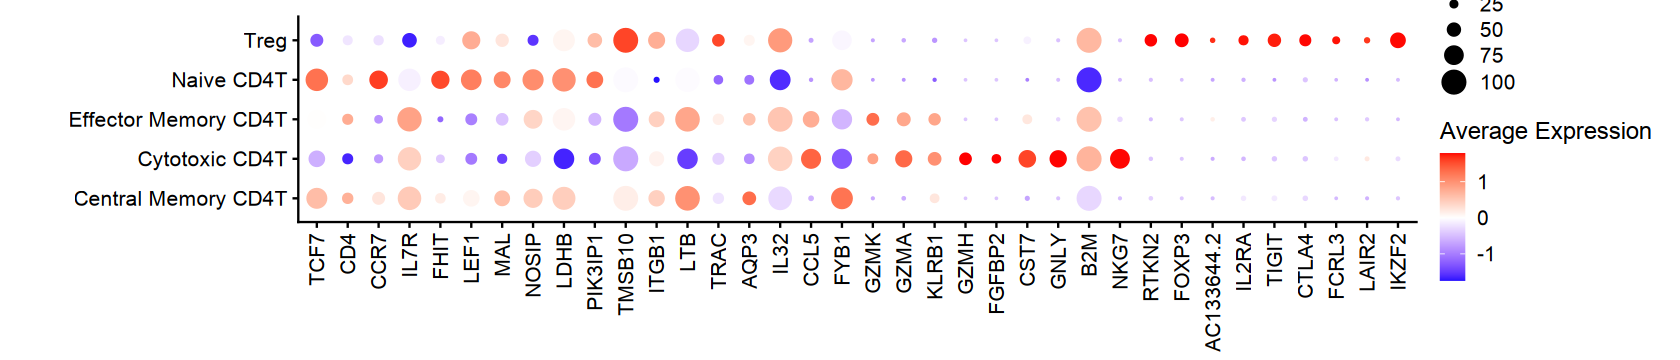

In [66]:
options(repr.plot.width=14, repr.plot.height=3)

p <- DotPlot(
  object = obj,
  features = features_to_plot,
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )

print(p)

# MS4A1''TNFRSF13B''IGHM''IGHD''AIM2''CD79A''LINC01857''RALGPS2''BANK1''CD79B'

Warning message in DoHeatmap(subset(obj, downsample = 100), features = features_to_plot, :
“The following features were omitted as they were not found in the scale.data slot for the RNA assay: FYB1, PIK3IP1, LDHB, CD4, TCF7”


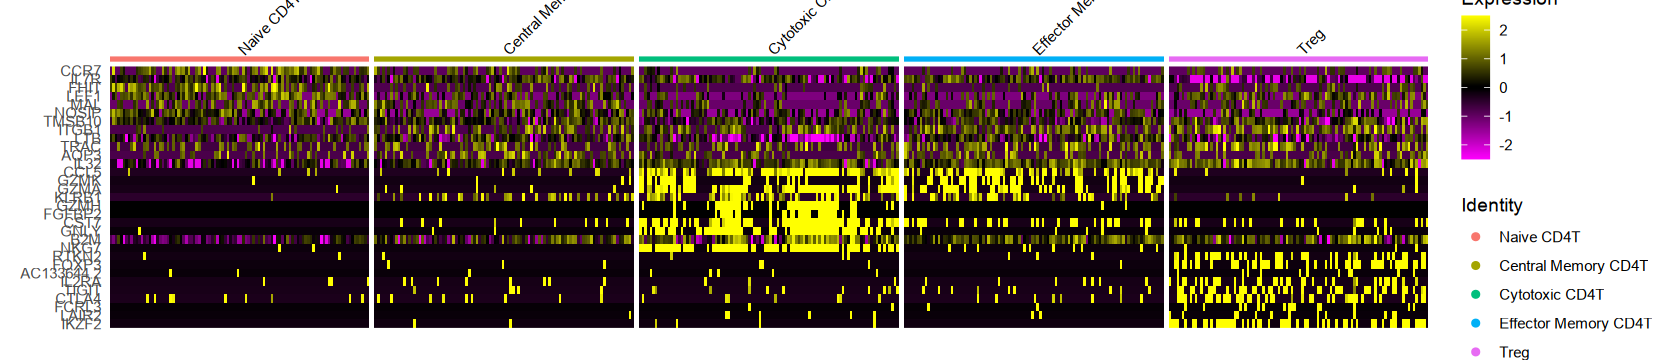

In [68]:
Idents(ft) =  "celltype_level3"

DoHeatmap(subset(obj, downsample = 100), 
          features = features_to_plot, size = 3)